<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/1_foundations/dynamics_relativity/dynrel_colab_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Dynamics and Relativity* — `dynrel_colab_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Dynamics and Relativity — Interactive Visualisation Notebook
**PSE Lab · SeoulTech**

This notebook provides seven interactive visualisations covering all seven chapters of the *Dynamics and Relativity* course.

| Plot | Chapter | Topic |
|------|---------|-------|
| 1 | Ch 1 | Phase Portrait — Newtonian Trajectories |
| 2 | Ch 2 | Potential Energy Landscape & Pendulum Phase Portrait |
| 3 | Ch 3 | Dimensional Analysis — Atomic Bomb Blast Radius Scaling |
| 4 | Ch 4 | Kepler Orbits — Effective Potential & Conic Sections |
| 5 | Ch 5 | Elastic Collisions & The Digits of π |
| 6 | Ch 6 | Coriolis Deflection on a Rotating Earth |
| 7 | Ch 7 | Spacetime Diagrams & Lorentz Transformations |


## Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch
from matplotlib.colors import Normalize
from matplotlib.collections import LineCollection
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor':   '#161b22',
    'axes.edgecolor':   '#30363d',
    'axes.labelcolor':  '#e6edf3',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'text.color':       '#e6edf3',
    'grid.color':       '#21262d',
    'grid.linewidth':   0.6,
    'lines.linewidth':  1.8,
    'font.size':        11,
    'axes.titlesize':   13,
    'axes.labelsize':   11,
    'legend.framealpha': 0.3,
    'legend.edgecolor': '#30363d',
})
GOLD   = '#f0c040'
GREEN  = '#3fb950'
BLUE   = '#58a6ff'
RED    = '#f85149'
PURPLE = '#bc8cff'
CYAN   = '#39d353'
ORANGE = '#ffa657'
print('Setup complete. Ready to run visualisations.')


Setup complete. Ready to run visualisations.


## Plot 1 · Chapter 1 — Phase Portrait: Newtonian Trajectories

Newton's second law $m\ddot{x} = F(x)$ is second-order, so the state of a particle is fully specified by the pair $(x, v) = (x, \dot{x})$. The **phase portrait** shows all trajectories in the $(x,v)$ plane.

| System | Potential | Equilibria |
|--------|-----------|------------|
| Harmonic oscillator | $V = \tfrac{1}{2}kx^2$ | Stable centre |
| Cubic potential | $V = x^3 - 3x$ | Stable + unstable |

**Reading the portrait:** closed curves = bounded (oscillatory) motion; open curves = escape. The separatrix (red) asymptotes to the unstable equilibrium.


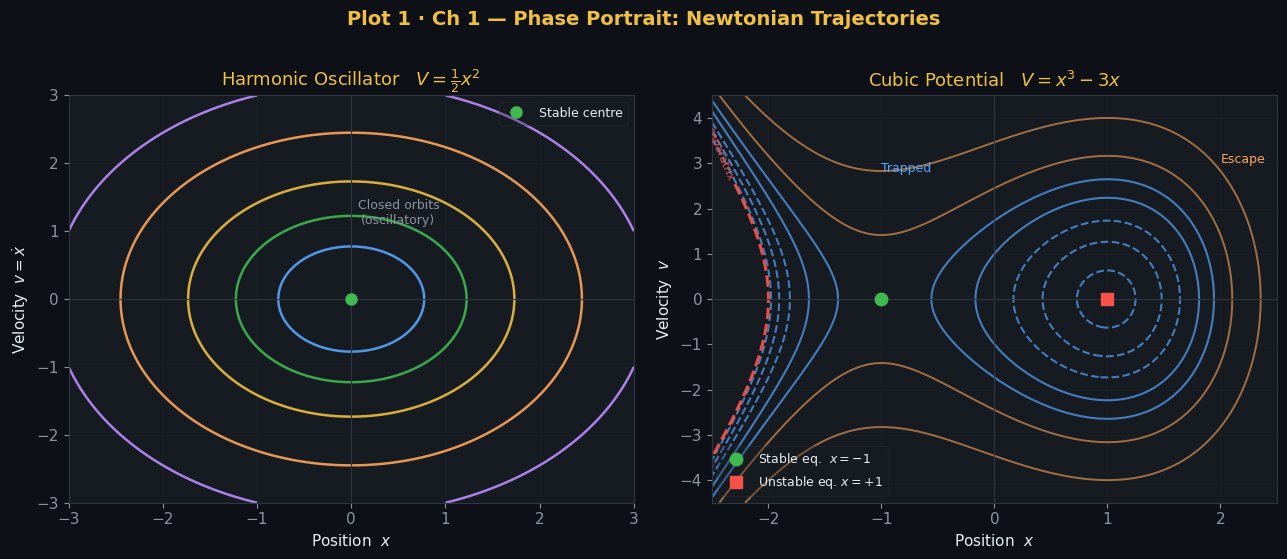

Plot 1 saved.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('Plot 1 · Ch 1 — Phase Portrait: Newtonian Trajectories',
             fontsize=14, color=GOLD, fontweight='bold', y=1.01)

# ---- Left: harmonic oscillator ---
ax = axes[0]
ax.set_title('Harmonic Oscillator   $V = \\frac{1}{2}x^2$', color=GOLD)
x_ho = np.linspace(-3, 3, 400)
v_ho = np.linspace(-3, 3, 400)
X, V = np.meshgrid(x_ho, v_ho)
E_HO = 0.5*V**2 + 0.5*X**2
energies = [0.3, 0.75, 1.5, 3.0, 5.0]
colors_ho = [BLUE, GREEN, GOLD, ORANGE, PURPLE]
for E_val, col in zip(energies, colors_ho):
    ax.contour(X, V, E_HO, levels=[E_val], colors=[col], linewidths=1.8, alpha=0.9)
ax.axhline(0, color='#30363d', lw=0.8)
ax.axvline(0, color='#30363d', lw=0.8)
ax.plot(0, 0, 'o', color=GREEN, ms=8, zorder=5, label='Stable centre')
ax.annotate('Closed orbits\n(oscillatory)', xy=(0.5, 1.1), color='#8b949e', fontsize=9, ha='center')
ax.set_xlabel('Position  $x$'); ax.set_ylabel('Velocity  $v = \\dot{x}$')
ax.legend(fontsize=9); ax.grid(True, alpha=0.4)
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)

# ---- Right: cubic potential V = x^3 - 3x ---
ax = axes[1]
ax.set_title('Cubic Potential   $V = x^3 - 3x$', color=GOLD)
x_c = np.linspace(-2.5, 2.5, 600)
v_c = np.linspace(-4.5, 4.5, 600)
Xc, Vc = np.meshgrid(x_c, v_c)
E_cub = 0.5*Vc**2 + (Xc**3 - 3*Xc)
for E_val in [-1.8, -1.2, -0.5, 0.5, 1.5]:
    try: ax.contour(Xc, Vc, E_cub, levels=[E_val], colors=[BLUE], linewidths=1.5, alpha=0.7)
    except: pass
try:
    cs = ax.contour(Xc, Vc, E_cub, levels=[-2.0], colors=[RED], linewidths=2.2, alpha=0.95)
    ax.clabel(cs, fmt={-2.0: 'separatrix'}, fontsize=8, colors=RED)
except: pass
for E_val in [3.0, 6.0]:
    try: ax.contour(Xc, Vc, E_cub, levels=[E_val], colors=[ORANGE], linewidths=1.4, alpha=0.6)
    except: pass
ax.plot(-1, 0, 'o', color=GREEN, ms=9, zorder=6, label='Stable eq.  $x=-1$')
ax.plot(+1, 0, 's', color=RED,   ms=9, zorder=6, label='Unstable eq. $x=+1$')
ax.annotate('Escape', xy=(2.0, 3.0), color=ORANGE, fontsize=9)
ax.annotate('Trapped', xy=(-1.0, 2.8), color=BLUE, fontsize=9)
ax.axhline(0, color='#30363d', lw=0.8); ax.axvline(0, color='#30363d', lw=0.8)
ax.set_xlabel('Position  $x$'); ax.set_ylabel('Velocity  $v$')
ax.legend(fontsize=9, loc='lower left'); ax.grid(True, alpha=0.4)
ax.set_xlim(-2.5, 2.5); ax.set_ylim(-4.5, 4.5)

plt.tight_layout()
plt.savefig('dynrel_plot1_phase_portrait.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 1 saved.')


## Plot 2 · Chapter 2 — Potential Energy Landscape & Pendulum Phase Portrait

Chapter 2 introduces **potential energy** $V(x)$ and the rule that a particle can only reach regions where $V(x) \leq E$. Turning points occur where $V = E$.

The pendulum $\ddot{\theta} = -(g/l)\sin\theta$ with $V(\theta) = -mgl\cos\theta$ shows:

- **Libration** ($E < mgl$): oscillation — closed orbits.
- **Rotation** ($E > mgl$): full circles — open (wrapping) orbits.
- **Separatrix** ($E = mgl$): boundary trajectory.


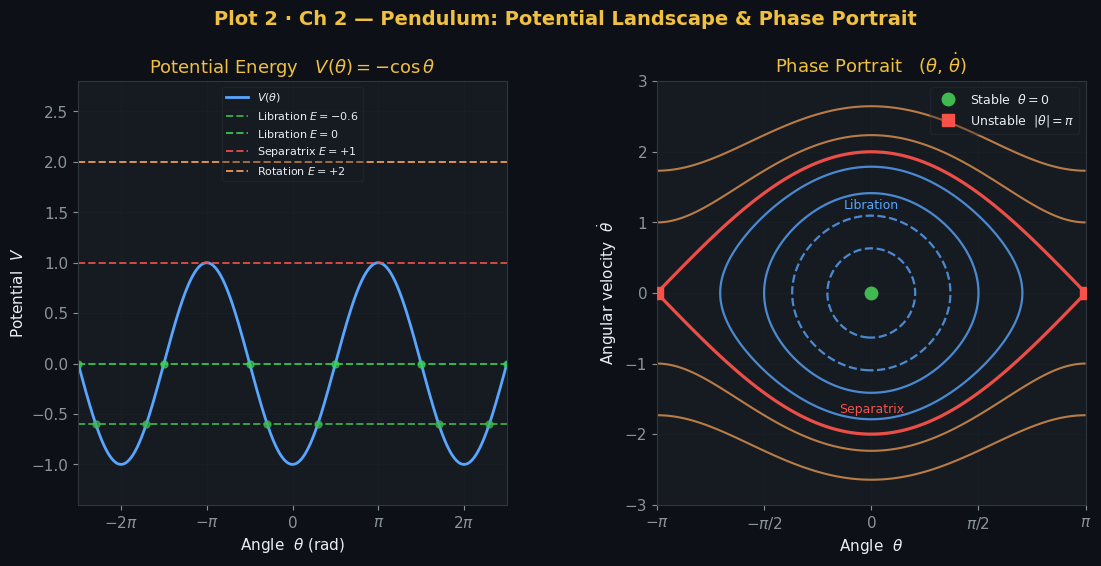

Plot 2 saved.


In [3]:
fig = plt.figure(figsize=(13, 5.5))
fig.suptitle('Plot 2 · Ch 2 — Pendulum: Potential Landscape & Phase Portrait',
             fontsize=14, color=GOLD, fontweight='bold', y=1.01)
gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.35)
ax_pot = fig.add_subplot(gs[0])
ax_pha = fig.add_subplot(gs[1])

# ---- Left: potential landscape ---
ax_pot.set_title('Potential Energy   $V(\\theta) = -\\cos\\theta$', color=GOLD)
theta_1d = np.linspace(-2.5*np.pi, 2.5*np.pi, 1000)
V_1d = -np.cos(theta_1d)
ax_pot.plot(theta_1d, V_1d, color=BLUE, lw=2, label='$V(\\theta)$')
E_levels = [('Libration $E=-0.6$', -0.6, GREEN),
            ('Libration $E=0$',     0.0, CYAN),
            ('Separatrix $E=+1$',   1.0, RED),
            ('Rotation $E=+2$',     2.0, ORANGE)]
for lbl, E_val, col in E_levels:
    ax_pot.axhline(E_val, color=col, lw=1.4, ls='--', alpha=0.85, label=lbl)
    if -1 < E_val < 1:
        tp = np.arccos(-E_val)
        for k in range(-2, 3):
            for s in [-1, 1]:
                xtp = s*tp + 2*np.pi*k
                if -2.5*np.pi <= xtp <= 2.5*np.pi:
                    ax_pot.plot(xtp, E_val, 'o', color=col, ms=5, alpha=0.7)
ax_pot.set_xlabel('Angle  $\\theta$ (rad)')
ax_pot.set_ylabel('Potential  $V$')
ax_pot.set_xlim(-2.5*np.pi, 2.5*np.pi); ax_pot.set_ylim(-1.4, 2.8)
ax_pot.set_xticks([-2*np.pi, -np.pi, 0, np.pi, 2*np.pi])
ax_pot.set_xticklabels(['$-2\\pi$','$-\\pi$','$0$','$\\pi$','$2\\pi$'])
ax_pot.legend(fontsize=8, loc='upper center'); ax_pot.grid(True, alpha=0.4)

# ---- Right: phase portrait ---
ax_pha.set_title('Phase Portrait   $(\\theta,\\,\\dot{\\theta})$', color=GOLD)
th_arr = np.linspace(-np.pi, np.pi, 700)
om_arr = np.linspace(-3.0, 3.0, 700)
TH, OM = np.meshgrid(th_arr, om_arr)
E_grid = 0.5*OM**2 - np.cos(TH)
for E_val in [-0.8, -0.4, 0.0, 0.6]:
    ax_pha.contour(TH, OM, E_grid, levels=[E_val], colors=[BLUE], linewidths=1.6, alpha=0.8)
ax_pha.contour(TH, OM, E_grid, levels=[1.0], colors=[RED], linewidths=2.3, alpha=0.95)
for E_val in [1.5, 2.5]:
    ax_pha.contour(TH, OM, E_grid, levels=[E_val], colors=[ORANGE], linewidths=1.5, alpha=0.7)
ax_pha.plot(0, 0, 'o', color=GREEN, ms=9, zorder=6, label='Stable  $\\theta=0$')
for xeq in [-np.pi, np.pi]:
    ax_pha.plot(xeq, 0, 's', color=RED, ms=9, zorder=6,
                label='Unstable  $|\\theta|=\\pi$' if xeq==-np.pi else '_')
ax_pha.set_xlabel('Angle  $\\theta$'); ax_pha.set_ylabel('Angular velocity  $\\dot{\\theta}$')
ax_pha.set_xlim(-np.pi, np.pi); ax_pha.set_ylim(-3, 3)
ax_pha.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax_pha.set_xticklabels(['$-\\pi$','$-\\pi/2$','$0$','$\\pi/2$','$\\pi$'])
ax_pha.annotate('Libration', xy=(0, 1.2), ha='center', color=BLUE, fontsize=9)
ax_pha.annotate('Separatrix', xy=(0, -1.7), ha='center', color=RED, fontsize=9)
ax_pha.legend(fontsize=9, loc='upper right'); ax_pha.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('dynrel_plot2_pendulum.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 2 saved.')


## Plot 3 · Chapter 3 — Dimensional Analysis: Atomic Bomb Blast Radius

G. I. Taylor (1950) extracted the yield of the first atomic bomb from declassified photographs using only dimensional analysis. The blast radius satisfies:

$$R = C\left(\frac{E}{\rho}\right)^{1/5} t^{2/5}$$

Plotting $\log R$ vs $\log t$ yields slope $2/5$, confirming the scaling law.


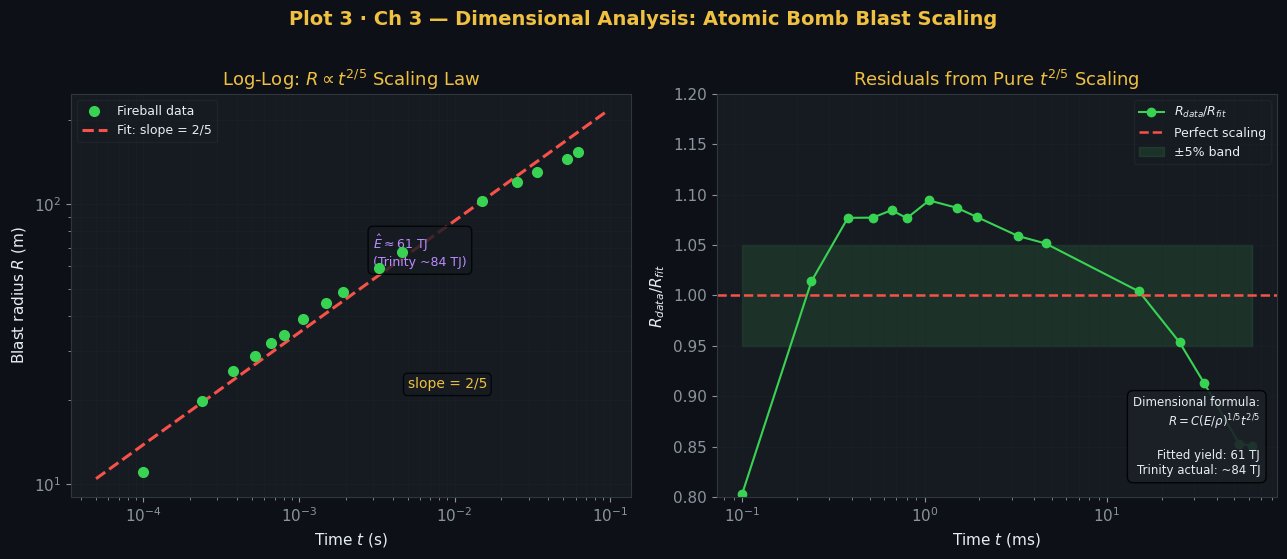

Plot 3 saved. Estimated bomb yield: 61 TJ


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('Plot 3 · Ch 3 — Dimensional Analysis: Atomic Bomb Blast Scaling',
             fontsize=14, color=GOLD, fontweight='bold', y=1.01)

# Taylor's approximate data (t in ms → s; R in m)
t_ms = np.array([0.10,0.24,0.38,0.52,0.66,0.80,1.06,1.50,
                  1.93,3.26,4.61,15.0,25.0,34.0,53.0,62.0])
R_m  = np.array([11.1,19.9,25.4,28.8,31.9,34.2,38.9,44.4,
                  48.7,59.0,67.3,103.0,120.0,130.0,145.0,154.0])
t_s  = t_ms * 1e-3

log_t = np.log10(t_s); log_R = np.log10(R_m)
intercept = np.mean(log_R - 0.4*log_t)
C_eff = 10**intercept
rho_air = 1.2
E_est = rho_air * C_eff**5
E_TJ  = E_est / 1e12

t_fine = np.logspace(np.log10(t_s.min()*0.5), np.log10(t_s.max()*1.5), 300)
R_fit  = C_eff * t_fine**0.4

# ---- Left: log-log ---
ax = axes[0]
ax.set_title('Log-Log: $R \\propto t^{2/5}$ Scaling Law', color=GOLD)
ax.loglog(t_s, R_m, 'o', color=CYAN, ms=7, label='Fireball data', zorder=5)
ax.loglog(t_fine, R_fit, '--', color=RED, lw=2.2, label='Fit: slope = 2/5')
ax.text(5e-3, 22, 'slope = 2/5', color=GOLD, fontsize=10,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#161b22', alpha=0.8))
ax.text(3e-3, 60, f'$\\hat{{E}} \\approx {E_TJ:.0f}$ TJ\n(Trinity ~84 TJ)',
        color=PURPLE, fontsize=9,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#161b22', alpha=0.8))
ax.set_xlabel('Time $t$ (s)'); ax.set_ylabel('Blast radius $R$ (m)')
ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.4)

# ---- Right: residuals ---
ax2 = axes[1]
ax2.set_title('Residuals from Pure $t^{2/5}$ Scaling', color=GOLD)
R_pred = C_eff * t_s**0.4
ratio  = R_m / R_pred
ax2.semilogx(t_ms, ratio, 'o-', color=CYAN, ms=6, lw=1.5, label='$R_{data}/R_{fit}$')
ax2.axhline(1.0, color=RED, lw=1.8, ls='--', label='Perfect scaling')
ax2.fill_between([t_ms.min(), t_ms.max()], [0.95]*2, [1.05]*2,
                 color=GREEN, alpha=0.15, label='±5% band')
ax2.set_xlabel('Time $t$ (ms)'); ax2.set_ylabel('$R_{data}/R_{fit}$')
ax2.set_ylim(0.8, 1.2); ax2.legend(fontsize=9); ax2.grid(True, which='both', alpha=0.4)
info = ('Dimensional formula:\n'
        '$R = C(E/\\rho)^{1/5}t^{2/5}$\n\n'
        f'Fitted yield: {E_TJ:.0f} TJ\n'
        'Trinity actual: ~84 TJ')
ax2.text(0.97, 0.05, info, transform=ax2.transAxes, fontsize=8.5,
         color='#e6edf3', ha='right', va='bottom',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#1c2128', alpha=0.9))

plt.tight_layout()
plt.savefig('dynrel_plot3_dimensional_analysis.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print(f'Plot 3 saved. Estimated bomb yield: {E_TJ:.0f} TJ')


## Plot 4 · Chapter 4 — Kepler Orbits: Effective Potential & Conic Sections

The central-force problem reduces to 1D motion in an **effective potential**:

$$V_{\rm eff}(r) = -\frac{GMm}{r} + \frac{L^2}{2mr^2}$$

The orbit shape from the **Binet equation** gives conic sections parameterised by eccentricity $e$:

| $e$ | Orbit | Energy |
|-----|-------|--------|
| $0$ | Circle | $E = E_{\min}$ |
| $0<e<1$ | Ellipse | $E_{\min}<E<0$ |
| $e=1$ | Parabola | $E=0$ |
| $e>1$ | Hyperbola | $E>0$ |


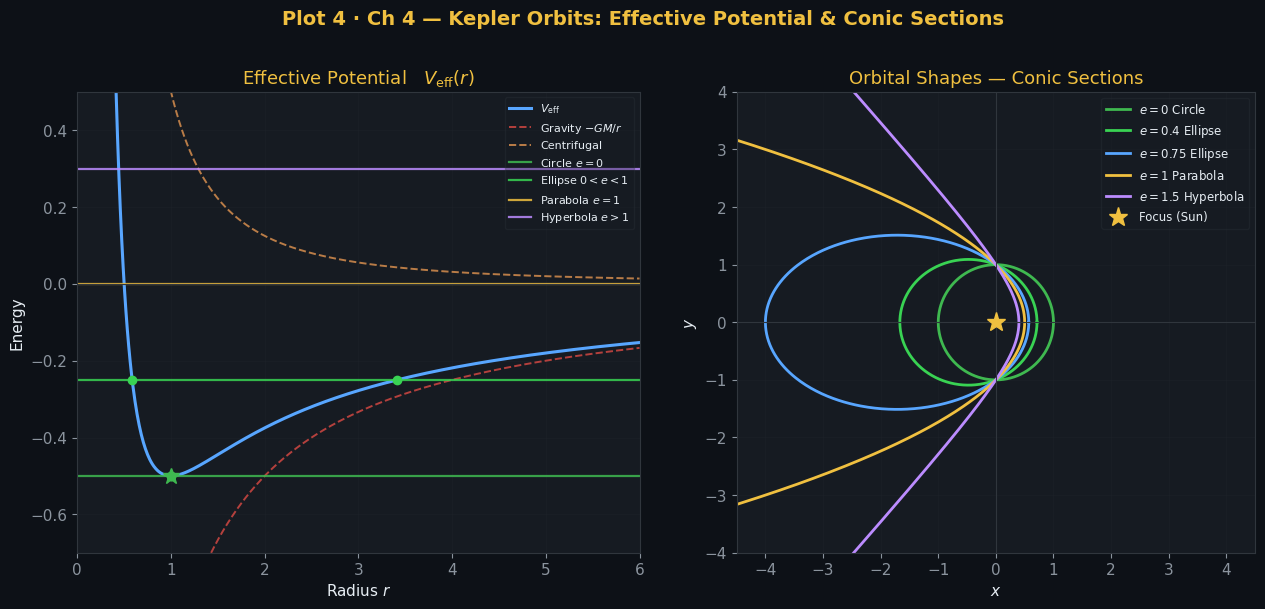

Plot 4 saved.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle('Plot 4 · Ch 4 — Kepler Orbits: Effective Potential & Conic Sections',
             fontsize=14, color=GOLD, fontweight='bold', y=1.01)

GM, L, m = 1.0, 1.0, 1.0
r_arr = np.linspace(0.05, 6.0, 800)
V_grav = -GM*m / r_arr
V_cent =  L**2 / (2*m*r_arr**2)
V_eff  = V_grav + V_cent

# ---- Left: effective potential ---
ax = axes[0]
ax.set_title('Effective Potential   $V_{\\rm eff}(r)$', color=GOLD)
ax.plot(r_arr, V_eff,  color=BLUE,   lw=2.2, label='$V_{\\rm eff}$')
ax.plot(r_arr, V_grav, color=RED,    lw=1.4, ls='--', alpha=0.7, label='Gravity $-GM/r$')
ax.plot(r_arr, V_cent, color=ORANGE, lw=1.4, ls='--', alpha=0.7, label='Centrifugal')
r_min  = L**2 / (GM*m**2)
E_circ = -GM**2*m**3/(2*L**2)
E_specs = [(E_circ, GREEN, 'Circle $e=0$'),
           (E_circ*0.5, CYAN, 'Ellipse $0<e<1$'),
           (0.0, GOLD, 'Parabola $e=1$'),
           (0.3, PURPLE, 'Hyperbola $e>1$')]
for E_val, col, lbl in E_specs:
    ax.axhline(E_val, color=col, lw=1.6, alpha=0.85, label=lbl)
    if E_val < 0:
        coeffs = [E_val, GM*m, -L**2/(2*m)]
        roots = np.roots(coeffs)
        for rr in roots:
            if np.isreal(rr) and rr.real > 0:
                ax.plot(rr.real, E_val, 'o', color=col, ms=6, zorder=5)
ax.plot(r_min, E_circ, '*', color=GREEN, ms=12, zorder=6)
ax.set_xlabel('Radius $r$'); ax.set_ylabel('Energy')
ax.set_xlim(0, 6); ax.set_ylim(-0.7, 0.5)
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.4); ax.axhline(0, color='#30363d', lw=0.8)

# ---- Right: orbital shapes ---
ax2 = axes[1]
ax2.set_title('Orbital Shapes — Conic Sections', color=GOLD)
p = L**2 / (GM*m**2)
ecc_specs = [(0.0,  GREEN,  '$e=0$ Circle'),
             (0.4,  CYAN,   '$e=0.4$ Ellipse'),
             (0.75, BLUE,   '$e=0.75$ Ellipse'),
             (1.0,  GOLD,   '$e=1$ Parabola'),
             (1.5,  PURPLE, '$e=1.5$ Hyperbola')]
for e, col, lbl in ecc_specs:
    if e < 1.0:
        phi = np.linspace(0, 2*np.pi, 800)
    else:
        phi_max = np.arccos(-1.0/e) - 0.02
        phi = np.linspace(-phi_max, phi_max, 800)
    r = p / (1 + e*np.cos(phi))
    ax2.plot(r*np.cos(phi), r*np.sin(phi), color=col, lw=2.0, label=lbl)
ax2.plot(0, 0, '*', color=GOLD, ms=14, zorder=6, label='Focus (Sun)')
ax2.set_xlabel('$x$'); ax2.set_ylabel('$y$')
ax2.set_xlim(-4.5, 4.5); ax2.set_ylim(-4, 4)
ax2.set_aspect('equal')
ax2.legend(fontsize=8.5, loc='upper right')
ax2.grid(True, alpha=0.4)
ax2.axhline(0, color='#30363d', lw=0.8); ax2.axvline(0, color='#30363d', lw=0.8)

plt.tight_layout()
plt.savefig('dynrel_plot4_kepler.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 4 saved.')


## Plot 5 · Chapter 5 — Elastic Collisions & The Digits of π

Two blocks collide elastically with a wall. If one block has mass $M = 100^n m$, the total number of collisions equals the first $n+1$ digits of π.

The key: conservation of energy and momentum maps $(v_1, v_2)$ to an ellipse. Each collision is a reflection, and the count equals $\lfloor \pi / \arctan(\sqrt{m/M}) \rfloor$.


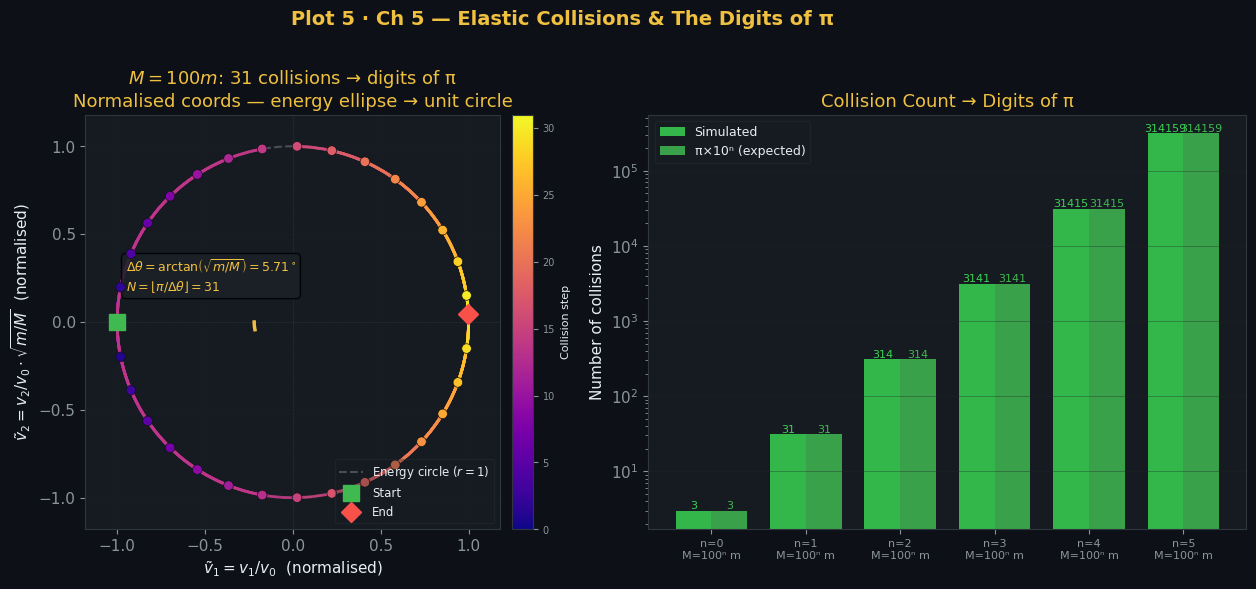

Plot 5 saved. Counts: [(0, 3), (1, 31), (2, 314), (3, 3141), (4, 31415), (5, 314159)]
Expected (π×10^n): [3, 31, 314, 3141, 31415, 314159]


In [6]:
def collide(M, m=1.0, v0=1.0, max_n=1000000):
    v1, v2 = -v0, 0.0
    count = 0
    for _ in range(max_n):
        if v2 >= 0 and v1 >= v2:
            break
        if v1 < v2:
            nv1 = ((M-m)*v1 + 2*m*v2) / (M+m)
            nv2 = (2*M*v1  + (m-M)*v2) / (M+m)
            v1, v2 = nv1, nv2
            count += 1
        elif v2 < 0:
            v2 = -v2
            count += 1
        else:
            break
    return count

def trajectory(M, m=1.0, v0=1.0, max_steps=2000):
    v1, v2 = -v0, 0.0
    pts = [(v1, v2)]
    for _ in range(max_steps):
        if v2 >= 0 and v1 >= v2:
            break
        if v1 < v2:
            nv1 = ((M-m)*v1 + 2*m*v2) / (M+m)
            nv2 = (2*M*v1  + (m-M)*v2) / (M+m)
            v1, v2 = nv1, nv2
        elif v2 < 0:
            v2 = -v2
        else:
            break
        pts.append((v1, v2))
    return np.array(pts)

import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
fig.suptitle('Plot 5 \u00b7 Ch 5 \u2014 Elastic Collisions & The Digits of \u03c0',
             fontsize=14, color=GOLD, fontweight='bold', y=1.01)

# ---- Left: arc-connected points on unit circle ---
# Normalise so the energy ellipse becomes the unit circle:
#   E = 0.5*M*v1^2 + 0.5*m*v2^2 = 0.5*M*v0^2
#   u1 = v1/v0,   u2 = v2/v0 * sqrt(m/M)  =>  u1^2 + u2^2 = 1
#
# In (u1,u2) space every collision step advances the point by a fixed angle
#   Delta-theta = arctan(sqrt(m/M))  around the circle.
# Total collisions  N = floor(pi / Delta-theta).
ax = axes[0]
M_demo, m_demo, v0 = 100.0, 1.0, 1.0
traj  = trajectory(M_demo, m_demo, v0)
n_col = len(traj) - 1

u1 = traj[:, 0] / v0
u2 = traj[:, 1] / v0 * np.sqrt(m_demo / M_demo)
angles = np.arctan2(u2, u1)

# Unit circle
phi = np.linspace(0, 2*np.pi, 500)
ax.plot(np.cos(phi), np.sin(phi), color='#484f58', lw=1.5, ls='--', label='Energy circle ($r=1$)')

# Connect consecutive points along the arc (not across the circle)
cmap = plt.get_cmap('plasma')
for i in range(len(angles) - 1):
    a0, a1 = angles[i], angles[i+1]
    # Always travel the shorter arc
    diff = a1 - a0
    if diff > np.pi:   a1 -= 2*np.pi
    elif diff < -np.pi: a1 += 2*np.pi
    arc_pts = np.linspace(a0, a1, 40)
    col = cmap(i / n_col)
    ax.plot(np.cos(arc_pts), np.sin(arc_pts), color=col, lw=2.0, alpha=0.9)

# Dots at each state
sc = ax.scatter(u1, u2, c=np.arange(len(u1)), cmap='plasma',
                norm=plt.Normalize(0, n_col), s=48, zorder=5,
                edgecolors='#0d1117', linewidths=0.5)
ax.plot(u1[0],  u2[0],  's', color=GREEN, ms=11, zorder=6, label='Start')
ax.plot(u1[-1], u2[-1], 'D', color=RED,   ms=10, zorder=6, label='End')

cb = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.02)
cb.set_label('Collision step', color='#e6edf3', fontsize=8)
cb.ax.tick_params(labelsize=7)

# Angle step annotation: small arc between first two points
dtheta   = np.arctan(np.sqrt(m_demo / M_demo))
dtheta_d = np.degrees(dtheta)
N_pred   = int(np.pi / dtheta)
r_arc    = 0.22
arc_ann  = np.linspace(angles[0], angles[1], 40)
# handle wrap
if angles[1] - angles[0] < -np.pi:
    arc_ann = np.linspace(angles[0], angles[1] + 2*np.pi, 40)
ax.plot(r_arc * np.cos(arc_ann), r_arc * np.sin(arc_ann), color=GOLD, lw=2.5, zorder=7)
ax.text(-0.95, 0.18,
        f'$\\Delta\\theta = \\arctan\\!\\left(\\sqrt{{m/M}}\\right) = {dtheta_d:.2f}^\\circ$\n'
        f'$N = \\lfloor\\pi/\\Delta\\theta\\rfloor = {N_pred}$',
        fontsize=9, color=GOLD,
        bbox=dict(boxstyle='round,pad=0.35', facecolor='#1c2128', alpha=0.88))

ax.axhline(0, color='#30363d', lw=0.6, ls=':')
ax.axvline(0, color='#30363d', lw=0.6, ls=':')
ax.set_xlabel('$\\tilde{v}_1 = v_1/v_0$  (normalised)')
ax.set_ylabel('$\\tilde{v}_2 = v_2/v_0 \\cdot\\sqrt{m/M}$  (normalised)')
ax.set_title(f'$M=100m$: {n_col} collisions \u2192 digits of \u03c0\n'
             f'Normalised coords \u2014 energy ellipse \u2192 unit circle', color=GOLD)
ax.legend(fontsize=8.5, loc='lower right')
ax.grid(True, alpha=0.3)
ax.set_aspect('equal')
ax.set_xlim(-1.18, 1.18); ax.set_ylim(-1.18, 1.18)

# ---- Right: collision count vs n ---
ax2 = axes[1]
n_vals = np.arange(0, 6)
M_vals = 100.0**n_vals
counts = [collide(M) for M in M_vals]
pi_exp = [int(np.pi * 10**n) for n in n_vals]
x_pos  = np.arange(len(n_vals)); width = 0.38
ax2.bar(x_pos - width/2, counts, width, color=CYAN,  alpha=0.85, label='Simulated')
ax2.bar(x_pos + width/2, pi_exp, width, color=GREEN, alpha=0.85, label='\u03c0\u00d710\u207f (expected)')
for xi, (c, p) in enumerate(zip(counts, pi_exp)):
    ax2.text(xi - width/2, c*1.05, str(c), ha='center', fontsize=8, color=CYAN)
    ax2.text(xi + width/2, p*1.05, str(p), ha='center', fontsize=8, color=GREEN)
ax2.set_xticks(x_pos)
ax2.set_xticklabels([f'n={n}\nM=100\u207f m' for n in n_vals], fontsize=8)
ax2.set_ylabel('Number of collisions')
ax2.set_title('Collision Count \u2192 Digits of \u03c0', color=GOLD)
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.4, axis='y'); ax2.set_yscale('log')

plt.tight_layout()
plt.savefig('dynrel_plot5_collisions_pi.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 5 saved. Counts:', list(zip(n_vals.tolist(), counts)))
print('Expected (\u03c0\u00d710^n):', pi_exp)


## Plot 6 · Chapter 6 — Coriolis Deflection on a Rotating Earth

In a rotating frame with angular velocity $\boldsymbol{\Omega}$:

$$m\ddot{\mathbf{r}} = \mathbf{F}_{\rm real} - m\boldsymbol{\Omega}\times(\boldsymbol{\Omega}\times\mathbf{r}) - 2m\boldsymbol{\Omega}\times\dot{\mathbf{r}}$$

The **Coriolis force** deflects moving objects to the **right** in the Northern Hemisphere and **left** in the Southern Hemisphere.

Left: eastward deflection of a dropped ball vs latitude for different heights.  
Right: inertial circle traced by a horizontally-launched particle at 45°N.


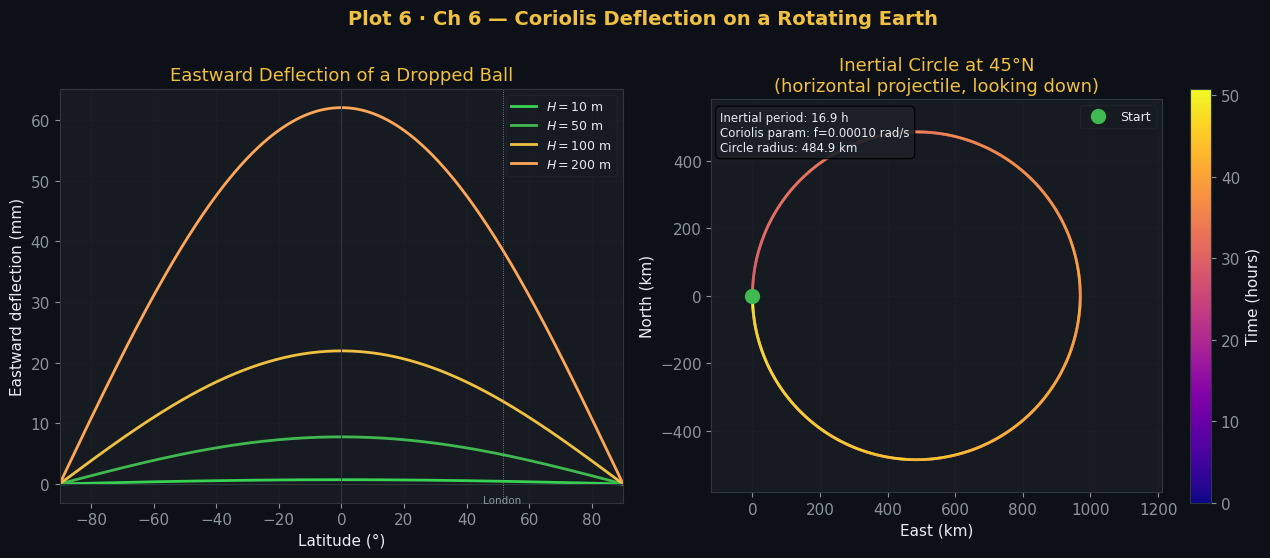

Plot 6 saved. Inertial period at 45N: 16.92 hours


In [7]:
Omega = 7.292e-5  # rad/s
g     = 9.81      # m/s^2

def drop_deflection_mm(H, lat_deg):
    lat = np.radians(lat_deg)
    return (1.0/3.0) * Omega * np.cos(lat) * np.sqrt(8*H**3/g) * 1000  # mm

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('Plot 6 · Ch 6 — Coriolis Deflection on a Rotating Earth',
             fontsize=14, color=GOLD, fontweight='bold', y=1.01)

# ---- Left: deflection vs latitude ---
ax = axes[0]
ax.set_title('Eastward Deflection of a Dropped Ball', color=GOLD)
lats = np.linspace(-90, 90, 300)
for H, col in zip([10, 50, 100, 200], [CYAN, GREEN, GOLD, ORANGE]):
    ax.plot(lats, [drop_deflection_mm(H, lat) for lat in lats],
            color=col, lw=2.0, label=f'$H={H}$ m')
ax.axhline(0, color='#30363d', lw=0.8)
ax.axvline(0, color='#30363d', lw=0.8)
ax.axvline(51.5, color='#8b949e', lw=0.6, ls=':')
ax.text(51.5, ax.get_ylim()[0] if ax.get_ylim()[0] != 0.0 else -5,
        'London', fontsize=7.5, color='#8b949e', ha='center')
ax.set_xlabel('Latitude (°)'); ax.set_ylabel('Eastward deflection (mm)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.4); ax.set_xlim(-90, 90)

# ---- Right: inertial circle at 45N ---
ax2 = axes[1]
ax2.set_title('Inertial Circle at 45°N\n(horizontal projectile, looking down)', color=GOLD)
lat_rad = np.radians(45)
f  = 2*Omega*np.sin(lat_rad)   # Coriolis parameter
v0 = 50.0                       # initial northward speed m/s
T  = 2*np.pi/f
t  = np.linspace(0, 3*T, 3000)
R_in = v0/f
x_in = R_in * (1 - np.cos(f*t))  # east
y_in = R_in * np.sin(f*t)         # north
pts  = np.array([x_in/1e3, y_in/1e3]).T.reshape(-1,1,2)
segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
lc   = LineCollection(segs, cmap='plasma', norm=Normalize(0, t.max()/3600), lw=2.0)
lc.set_array(t[:-1]/3600)
ax2.add_collection(lc)
cb = plt.colorbar(lc, ax=ax2)
cb.set_label('Time (hours)', color='#e6edf3')
ax2.plot(0, 0, 'o', color=GREEN, ms=10, zorder=6, label='Start')
xlim = R_in/1e3 * 2.5
ax2.set_xlim(-xlim*0.1, xlim); ax2.set_ylim(-R_in/1e3*1.2, R_in/1e3*1.2)
ax2.set_aspect('equal')
ax2.set_xlabel('East (km)'); ax2.set_ylabel('North (km)')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.4)
ax2.text(0.02, 0.97,
         f'Inertial period: {T/3600:.1f} h\nCoriolis param: f={f:.5f} rad/s\nCircle radius: {R_in/1e3:.1f} km',
         transform=ax2.transAxes, fontsize=8.5, va='top',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#1c2128', alpha=0.9))

plt.tight_layout()
plt.savefig('dynrel_plot6_coriolis.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print(f'Plot 6 saved. Inertial period at 45N: {T/3600:.2f} hours')


## Plot 7 · Chapter 7 — Spacetime Diagrams & Lorentz Transformations

Special relativity replaces Galilean boosts with **Lorentz transformations** ($c=1$):

$$t' = \gamma(t - \beta x), \qquad x' = \gamma(x - \beta t), \qquad \gamma = \frac{1}{\sqrt{1-\beta^2}}$$

Key features of the spacetime diagram:
- **Light cone**: $t^2 - x^2 = 0$ — the causal boundary.
- **Moving frames**: the $t'$- and $x'$-axes are both tilted toward the light cone.
- **Invariant hyperbolas**: $t^2 - x^2 = s^2 = \text{const}$.


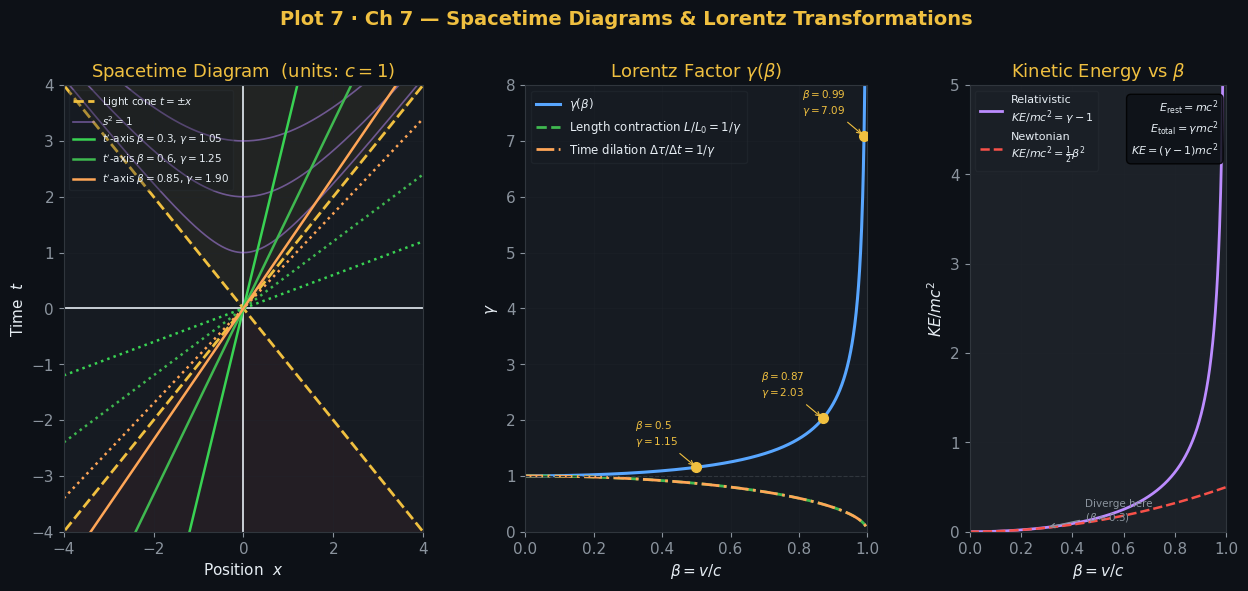

Plot 7 saved.


In [8]:
import numpy as np
fig = plt.figure(figsize=(15, 5.8))
fig.suptitle('Plot 7 \u00b7 Ch 7 \u2014 Spacetime Diagrams & Lorentz Transformations',
             fontsize=14, color=GOLD, fontweight='bold', y=1.01)

# Three panels: spacetime diagram | gamma(beta) | kinetic energy inset
from matplotlib.gridspec import GridSpec
gs = GridSpec(1, 3, figure=fig, width_ratios=[1.05, 1.0, 0.75], wspace=0.32)
ax_st  = fig.add_subplot(gs[0])   # spacetime diagram
ax_gam = fig.add_subplot(gs[1])   # gamma(beta)
ax_ke  = fig.add_subplot(gs[2])   # kinetic energy comparison

# ── Left: spacetime diagram ───────────────────────────────────────────────────
ax = ax_st
ax.set_title('Spacetime Diagram  (units: $c=1$)', color=GOLD)
ax.axhline(0, color='#e6edf3', lw=1.2)
ax.axvline(0, color='#e6edf3', lw=1.2)
x_lc = np.linspace(-5, 5, 100)
ax.plot(x_lc,  x_lc, color=GOLD, lw=2.0, ls='--', label='Light cone $t=\\pm x$')
ax.plot(x_lc, -x_lc, color=GOLD, lw=2.0, ls='--')
x_hyp = np.linspace(0.01, 5.0, 500)
for s2 in [1, 4, 9]:
    ct_hyp = np.sqrt(x_hyp**2 + s2)
    label = f'$s^2={s2}$' if s2 == 1 else '_'
    ax.plot( x_hyp,  ct_hyp, color=PURPLE, lw=1.2, alpha=0.5, label=label)
    ax.plot(-x_hyp,  ct_hyp, color=PURPLE, lw=1.2, alpha=0.5)
betas = [0.3, 0.6, 0.85]
frame_cols = [CYAN, GREEN, ORANGE]
for beta, col in zip(betas, frame_cols):
    gamma = 1/np.sqrt(1-beta**2)
    t_r = np.linspace(-4, 4, 100)
    ax.plot(beta*t_r, t_r, color=col, lw=1.8,
            label=f"$t'$-axis $\\beta={beta}$, $\\gamma={gamma:.2f}$")
    x_r = np.linspace(-4, 4, 100)
    ax.plot(x_r, beta*x_r, color=col, lw=1.8, ls=':')
x_fill = np.linspace(-5, 5, 500)
ax.fill_between(x_fill,  np.abs(x_fill), 5,  alpha=0.06, color=GOLD)
ax.fill_between(x_fill, -5, -np.abs(x_fill), alpha=0.06, color=RED)
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
ax.set_xlabel('Position  $x$')
ax.set_ylabel('Time  $t$')
ax.legend(fontsize=7.5, loc='upper left')
ax.grid(True, alpha=0.4)

# ── Middle: gamma(beta) ───────────────────────────────────────────────────────
ax = ax_gam
ax.set_title('Lorentz Factor $\\gamma(\\beta)$', color=GOLD)
beta_arr  = np.linspace(0, 0.999, 1000)
gamma_arr = 1/np.sqrt(1-beta_arr**2)
ax.plot(beta_arr, gamma_arr,   color=BLUE,   lw=2.2, label='$\\gamma(\\beta)$')
ax.plot(beta_arr, 1/gamma_arr, color=GREEN,  lw=2.0, ls='--',
        label='Length contraction $L/L_0 = 1/\\gamma$')
ax.plot(beta_arr, 1/gamma_arr, color=ORANGE, lw=2.0, ls='-.',
        label='Time dilation $\\Delta\\tau/\\Delta t = 1/\\gamma$')
ax.axhline(1, color='#30363d', lw=0.8, ls='--')
for b0, lbl in [(0.5, '0.5c'), (0.87, '0.87c'), (0.99, '0.99c')]:
    g0 = 1/np.sqrt(1-b0**2)
    ax.plot(b0, g0, 'o', color=GOLD, ms=7, zorder=5)
    ax.annotate(f'$\\beta={b0}$\n$\\gamma={g0:.2f}$', xy=(b0, g0),
                xytext=(b0-0.18, g0+0.4), fontsize=7.5, color=GOLD,
                arrowprops=dict(arrowstyle='->', color=GOLD, lw=0.8))
ax.set_xlabel('$\\beta = v/c$')
ax.set_ylabel('$\\gamma$')
ax.set_xlim(0, 1); ax.set_ylim(0, 8)
ax.legend(fontsize=8.5, loc='upper left')
ax.grid(True, alpha=0.4)

# ── Right: kinetic energy comparison ─────────────────────────────────────────
ax = ax_ke
ax.set_facecolor('#1c2128')
ax.set_title('Kinetic Energy vs $\\beta$', color=GOLD)
ax.plot(beta_arr, gamma_arr - 1,       color=PURPLE, lw=2.0,
        label='Relativistic\n$KE/mc^2 = \\gamma - 1$')
ax.plot(beta_arr, 0.5*beta_arr**2,     color=RED,    lw=1.8, ls='--',
        label='Newtonian\n$KE/mc^2 = \\frac{1}{2}\\beta^2$')
# Mark where they diverge noticeably
b_div = 0.3
ke_rel = 1/np.sqrt(1-b_div**2) - 1
ke_new = 0.5*b_div**2
ax.annotate('Diverge here\n($\\beta\\approx0.3$)',
            xy=(b_div, ke_rel), xytext=(0.45, 0.12),
            fontsize=7.5, color='#8b949e',
            arrowprops=dict(arrowstyle='->', color='#8b949e', lw=0.9))
ax.set_xlabel('$\\beta = v/c$')
ax.set_ylabel('$KE/mc^2$')
ax.set_xlim(0, 1); ax.set_ylim(0, 5)
ax.legend(fontsize=8, loc='upper left')
ax.grid(True, alpha=0.35)

# Annotation: rest energy
ax.text(0.97, 0.97,
        '$E_{\\rm rest} = mc^2$\n$E_{\\rm total} = \\gamma mc^2$\n$KE = (\\gamma-1)mc^2$',
        transform=ax.transAxes, fontsize=8, color='#e6edf3',
        ha='right', va='top',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#0d1117', alpha=0.85))

plt.tight_layout()
plt.savefig('dynrel_plot7_spacetime.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 7 saved.')


---
## Summary

| Plot | Chapter | Key Physics |
|------|---------|-------------|
| 1 | Ch 1 | Phase portrait — state space, separatrix, closed vs open orbits |
| 2 | Ch 2 | Pendulum — potential landscape, libration vs rotation |
| 3 | Ch 3 | Atomic bomb scaling — $R \propto E^{1/5}\rho^{-1/5}t^{2/5}$ |
| 4 | Ch 4 | Kepler orbits — effective potential, conic sections |
| 5 | Ch 5 | Elastic collisions — π digits from mass ratio $M = 100^n m$ |
| 6 | Ch 6 | Coriolis force — deflection vs latitude, inertial circles |
| 7 | Ch 7 | Spacetime diagram — Lorentz transformation, γ(β) effects |

**PSE Lab · SeoulTech · Dynamics and Relativity**
